# EN3160 – Assignment 2: Fitting and Alignment

**Name:** Ransara Maldeniya  |  **Index No:** 230390A  |  **GitHub:** https://github.com/ransara3/EN3160-Assignment-2-Fitting-and-Alignment.git



In [13]:
import glob, os
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import minimize

plt.rcParams["figure.dpi"] = 110
def show(img_bgr, title="", figsize=(9, 6)):
    plt.figure(figsize=figsize); plt.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
    plt.title(title); plt.axis("off"); plt.show()

---
# Q1 – Blob detection with LoG and scale-space extrema

**Theory.** A blob of radius $r$ gives a maximum response to a Laplacian of Gaussian (LoG) when
$\sigma = r/\sqrt{2}$. To compare responses across scales we use the **scale-normalised LoG**
$\sigma^2\,\nabla^2 G_\sigma * I$. We build a stack over $\sigma_i = \sigma_0 k^i$ (geometric spacing), and a blob is a
**local extremum in $(x, y, \sigma)$** (26 neighbours). Its radius is $r=\sqrt{2}\,\sigma$.

**Pipeline:** gray image → for each σ: Gaussian blur + Laplacian, multiply by σ² → 3-D non-maximum suppression
(3×3×3) + threshold → drop overlapping circles (keep the stronger) → draw circles → report the largest.

Sunflower heads are *bright* blobs, so we detect maxima of $-\sigma^2\nabla^2 G * I$. No `cv2.HoughCircles` is used.

In [14]:
# CONFIG ---------------------------------------------------------------
IMG_PATH   = "images/the_berry_farms_sunflower_field.jpeg"
SIGMA_MIN  = 3.0      # smallest sigma  -> r_min = sqrt(2)*SIGMA_MIN
SIGMA_MAX  = 40.0     # largest  sigma  -> r_max = sqrt(2)*SIGMA_MAX
N_SCALES   = 20       # number of scales in the stack (geometric spacing)
THRESH     = 0.05     # min normalised-LoG response (image scaled to [0,1])
BRIGHT     = True     # True: bright blobs on dark bg, False: dark blobs
# ----------------------------------------------------------------------

im = cv.imread(IMG_PATH, cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, f"Could not read {IMG_PATH}"
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
print("image size (H,W):", gray.shape)

sigmas = np.geomspace(SIGMA_MIN, SIGMA_MAX, N_SCALES)

def log_scale_space(gray, sigmas, bright=True):
    stack = np.empty((len(sigmas),) + gray.shape, np.float32)
    sign = -1.0 if bright else 1.0
    for i, s in enumerate(sigmas):
        g = cv.GaussianBlur(gray, (0, 0), s)
        stack[i] = sign * (s ** 2) * cv.Laplacian(g, cv.CV_32F, ksize=1)
    return stack

def detect_blobs(stack, sigmas, thresh, overlap_factor=1.0):
    mx = ndi.maximum_filter(stack, size=(3, 3, 3), mode="nearest")
    peaks = (stack == mx) & (stack > thresh)
    peaks[0] = False; peaks[-1] = False          # need a neighbour scale on both sides
    idx = np.argwhere(peaks)                      # (scale, y, x)
    resp = stack[peaks]
    order = np.argsort(-resp)
    blobs = [(x, y, sigmas[s], np.sqrt(2) * sigmas[s], r)
             for (s, y, x), r in zip(idx[order], resp[order])]
    # prune overlapping blobs (keep the stronger one)
    kept = []
    for b in blobs:
        if all(np.hypot(b[0] - k[0], b[1] - k[1]) > overlap_factor * max(b[3], k[3]) for k in kept):
            kept.append(b)
    return kept

stack = log_scale_space(gray, sigmas, BRIGHT)
blobs = detect_blobs(stack, sigmas, THRESH)
H, W = gray.shape
margin = 0.5   # allow at most 50% of the radius to fall outside the image
blobs = [b for b in blobs
         if b[0] - margin*b[3] >= 0 and b[1] - margin*b[3] >= 0
         and b[0] + margin*b[3] < W and b[1] + margin*b[3] < H]
print(f"sigma range used: [{sigmas[0]:.2f}, {sigmas[-1]:.2f}]  ({N_SCALES} scales, k = {sigmas[1]/sigmas[0]:.3f})")
print("blobs detected:", len(blobs))

image size (H,W): (360, 360)
sigma range used: [3.00, 40.00]  (20 scales, k = 1.146)
blobs detected: 96


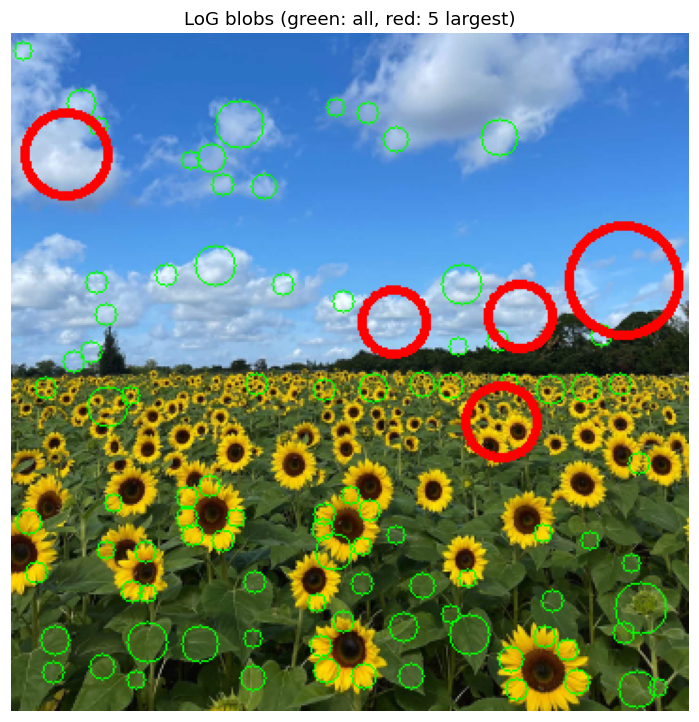

Largest circles:
 #      x      y   sigma   radius=sqrt2*sigma  response
 1    325    131   20.23                28.61     0.136
 2     29     64   15.40                21.78     0.144
 3    260    206   13.44                19.01     0.109
 4    270    150   11.73                16.58     0.181
 5    203    153   11.73                16.58     0.134


In [15]:
# draw all circles, highlight the 5 largest
largest = sorted(blobs, key=lambda b: -b[3])[:5]
out = im.copy()
for x, y, s, r, _ in blobs:
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 255, 0), 1)
for x, y, s, r, _ in largest:
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 0, 255), 3)
show(out, "LoG blobs (green: all, red: 5 largest)", (11, 8))

print("Largest circles:")
print(f"{'#':>2} {'x':>6} {'y':>6} {'sigma':>7} {'radius=sqrt2*sigma':>20} {'response':>9}")
for i, (x, y, s, r, resp) in enumerate(largest, 1):
    print(f"{i:>2} {x:>6.0f} {y:>6.0f} {s:>7.2f} {r:>20.2f} {resp:>9.3f}")


### Q1 – Discussion (fill in with your numbers)
* **σ range:** the cell above prints it (default 3 → 40, i.e. radii ≈ 4.2 → 56.6 px on the ¼-size image). The lower bound is set by the
  smallest sunflower head visible in the reduced image, the upper bound by the biggest head; make sure the largest circle is **not** at the last scale
  (extrema on the boundary scales are discarded, so widen `SIGMA_MAX` if the biggest blob disappears).
* **Largest circles:** report the table of (x, y, σ, r) printed above.
* **Parameters that matter:** `THRESH` trades missed flow### Q1 – Discussion

**σ range used:** σ ∈ [3, 40], 20 scales, geometric spacing (k = 1.146). This corresponds to radii r = √2·σ ∈ [4.2, 56.6] px on the ¼-size image (360×360).

**Blobs detected:** 96 after thresholding (0.05 on the scale-normalised response), 3-D non-maximum suppression, overlap pruning and removal of blobs whose circle falls mostly outside the image.

**Largest circles (x, y, σ, r = √2σ):**

| # | x | y | σ | r (px) | response |
|---|---|---|---|---|---|
| 1 | 325 | 131 | 20.23 | 28.61 | 0.136 |
| 2 | 29 | 64 | 15.40 | 21.78 | 0.144 |
| 3 | 260 | 206 | 13.44 | 19.01 | 0.109 |
| 4 | 270 | 150 | 11.73 | 16.58 | 0.181 |
| 5 | 203 | 153 | 11.73 | 16.58 | 0.134 |

The largest circle has σ = 20.23 and r ≈ 28.6 px, centred at (325, 131).

**Border artifacts.** Before filtering, the three largest detections (σ = 34.9, 26.6 and 20.2) were centred within 2 px of the image edge, so most of each circle lay outside the image. Their response came from the boundary handling of the Gaussian/Laplacian (replicated border pixels look like one large bright or dark region at high σ), not from a sunflower head. Discarding blobs with more than 50% of their radius outside the image removed these and 15 other border detections.

**Adequacy of the σ range.** The largest valid blob is at σ ≈ 20, well inside [3, 40], and the detected scales span σ ≈ 11.7–20.2. Since extrema at the first and last scale are discarded, the fact that no valid blob sits near σ = 40 shows the upper bound is not truncating real flowers. The lower bound of 3 (r ≈ 4 px) is below the smallest visible head, so small heads are covered.

**Response vs. size.** The strongest response among the top five is #4 (0.181, σ = 11.7), not the largest circle. The scale-normalised response depends on contrast as well as scale, so a smaller, high-contrast head can outrank a larger, lower-contrast one. Radius, not response, is therefore used to rank "largest" here. Circles #4 and #5 share σ = 11.73 and are 67 px apart (about 2 radii), which suggests neighbouring heads of similar size, since the pruning step only suppresses overlapping circles.

**Effect of the parameters.**
* `THRESH` trades missed flowers against false blobs on leaves, shadows and texture. Detections with low response (near 0.05) are mostly texture; the strong ones are the reliable heads.
* Geometric σ spacing keeps relative scale resolution constant (each step changes the radius by 14.6%).
* 3-D non-maximum suppression assigns each blob its characteristic scale instead of reporting it at every scale where it responds; overlap pruning keeps only the stronger of two overlapping circles.

**Limitations.** LoG responds to any roughly circular bright region, so bright sky, highlights, and tilted, overlapping or occluded heads can give wrong centres or radii. Partially visible heads at the image border are removed, so flowers cut off by the frame are not reported.ers vs. false blobs on texture (leaves, shadows); geometric σ spacing keeps relative scale
  resolution constant; the 3-D NMS ensures each blob is reported at its characteristic scale rather than at every scale where it responds.
* **Limitations:** LoG responds to any bright, roughly circular region, so bright sky/patches or tilted/occluded heads can give wrong radii; overlapping heads are merged by the pruning step.

---
# Q2 – RANSAC line and circle fitting

First we generate the noisy point set from Listing 1 (100 points: 50 on a noisy circle centre (2,3), r=10, radial σ = r/16 = 0.625; 50 on a noisy line y = −x + 2 with σ = 1).

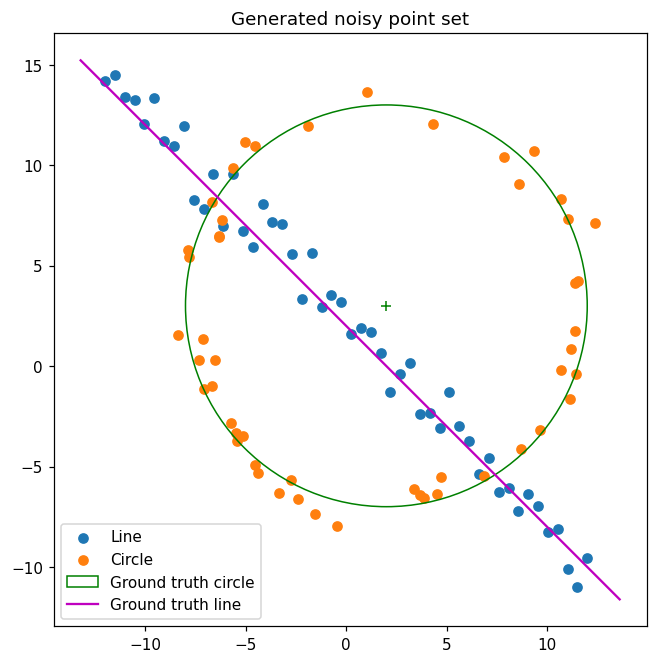

In [16]:
np.random.seed(0)           # comment out for a different random set each run
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.0
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))

fig, ax = plt.subplots(1, 1, figsize=(7, 7))
ax.scatter(X_line[:, 0], X_line[:, 1], label="Line")
ax.scatter(X_circ[:, 0], X_circ[:, 1], label="Circle")
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color="g", fill=False, label="Ground truth circle"))
ax.plot(x0_gt, y0_gt, "+", color="g")
x_ = np.array(ax.get_xlim()); ax.plot(x_, m * x_ + b, color="m", label="Ground truth line")
ax.set_aspect("equal"); ax.legend(); ax.set_title("Generated noisy point set"); plt.show()

## Q2(a) – RANSAC line (own implementation)

**Model.** Line $ax+by=d$ with $\|[a,b]^\top\|=1$. From a 2-point sample, the normal is the direction rotated by 90°, **normalised** (this enforces the unit-norm constraint),
and $d=[a,b]\cdot p_1$. **Error** = perpendicular distance $|ax_i+by_i-d|$.
After RANSAC, the best consensus set is refined by **total least squares**: with centroid $\mu$, $[a,b]$ is the right singular vector of $(P-\mu)$ for the
smallest singular value (automatically unit norm), and $d=[a,b]\cdot\mu$.

**Choosing the parameters.**
* *Threshold:* line noise σ = 1, so a threshold of **1.5** (≈1.5σ) keeps ~87 % of true line points while limiting contamination from circle points.
* *Min consensus:* 50 points truly lie on the line → expect ≈43–55 inliers (a few circle points near the crossings also fit); require **≥ 35** (70 % of the line points).
* *Iterations:* $N=\dfrac{\log(1-p)}{\log(1-w^{s})}$ with $s=2$, $p=0.999$, pessimistic $w=0.4$ (inlier ratio) → ≈40; we use at least 200 since iterations are cheap.

In [17]:

def n_iters(p, w, s):
    return int(np.ceil(np.log(1 - p) / np.log(1 - w ** s)))

# ---------------- line ----------------
def line_from_2pts(p1, p2):
    dx, dy = p2 - p1
    nrm = np.array([-dy, dx]); L = np.linalg.norm(nrm)
    if L < 1e-9: return None
    a, b = nrm / L                       # unit normal  (||[a,b]|| = 1)
    d = a * p1[0] + b * p1[1]
    if d < 0: a, b, d = -a, -b, -d       # keep d >= 0
    return a, b, d

def line_error(P, a, b, d):
    return np.abs(P @ np.array([a, b]) - d)   # perpendicular distance

def line_tls(P):
    mu = P.mean(0)
    _, _, Vt = np.linalg.svd(P - mu)
    a, b = Vt[-1]                        # smallest singular vector -> unit normal
    d = a * mu[0] + b * mu[1]
    if d < 0: a, b, d = -a, -b, -d
    return a, b, d

def ransac_line(P, thresh, min_inliers, iters, rng=np.random.default_rng(1)):
    best = dict(count=-1)
    for _ in range(iters):
        i = rng.choice(len(P), 2, replace=False)
        mdl = line_from_2pts(P[i[0]], P[i[1]])
        if mdl is None: continue
        err = line_error(P, *mdl)
        inl = err < thresh
        cnt = inl.sum()
        score = err[inl].mean() if cnt else np.inf
        if cnt > best["count"] or (cnt == best["count"] and score < best["score"]):
            best = dict(count=cnt, score=score, sample=i, sample_model=mdl, inliers=inl)
    if best["count"] < min_inliers:
        print("WARNING: consensus smaller than min_inliers")
    best["model"] = line_tls(P[best["inliers"]])           # refit on consensus (TLS)
    return best

# CONFIG ---------------------------------------------------------------
LINE_THRESH, LINE_MIN = 1.5, 35
LINE_ITERS = max(200, n_iters(0.999, 0.4, 2))
# ----------------------------------------------------------------------
res_line = ransac_line(X, LINE_THRESH, LINE_MIN, LINE_ITERS)
a, b, d = res_line["model"]
print(f"iterations={LINE_ITERS}, line inliers={res_line['count']}")
print(f"best line: a={a:.4f}, b={b:.4f}, d={d:.4f}, ||[a,b]||={np.hypot(a,b):.6f}")
print(f"ground truth (y=-x+2): a={1/np.sqrt(2):.4f}, b={1/np.sqrt(2):.4f}, d={2/np.sqrt(2):.4f}")

iterations=200, line inliers=55
best line: a=0.7195, b=0.6945, d=1.5467, ||[a,b]||=1.000000
ground truth (y=-x+2): a=0.7071, b=0.7071, d=1.4142


## Q2(b) – Remove the line consensus, then RANSAC circle on the remnant

**Model.** A circle through 3 points: from $|p_i-c|^2=r^2$, subtracting equations gives a 2×2 linear system for the centre $c$, then $r=|p_1-c|$.
**Error** = radial error $\big|\,\|p_i-c\|-r\,\big|$. The best consensus is refined with `scipy.optimize.minimize` on $\sum(\|p_i-c\|-r)^2$, initialised from the sample circle.

**Choosing the parameters.**
* *Threshold:* radial noise σ = r/16 = 0.625 → **1.25** (≈2σ, ~95 % of true circle points).
* *Min consensus:* 50 circle points → expect ≈47 inliers; require **≥ 35**.
* *Iterations:* $s=3$, $p=0.999$, $w=0.4$ → ≈105; we use at least 500.

In [18]:
def circle_from_3pts(p1, p2, p3):
    A = 2 * np.array([p2 - p1, p3 - p1])
    if abs(np.linalg.det(A)) < 1e-9: return None          # collinear
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    c = np.linalg.solve(A, rhs)
    return c[0], c[1], np.linalg.norm(p1 - c)

def circle_error(P, cx, cy, rad):
    return np.abs(np.hypot(P[:, 0] - cx, P[:, 1] - cy) - rad)   # radial error

def circle_refine(P, init):
    cost = lambda q: np.sum((np.hypot(P[:, 0] - q[0], P[:, 1] - q[1]) - q[2]) ** 2)
    return minimize(cost, init, method="BFGS").x

def ransac_circle(P, thresh, min_inliers, iters, rng=np.random.default_rng(2)):
    best = dict(count=-1)
    for _ in range(iters):
        i = rng.choice(len(P), 3, replace=False)
        mdl = circle_from_3pts(*P[i])
        if mdl is None: continue
        err = circle_error(P, *mdl)
        inl = err < thresh
        cnt = inl.sum()
        score = err[inl].mean() if cnt else np.inf
        if cnt > best["count"] or (cnt == best["count"] and score < best["score"]):
            best = dict(count=cnt, score=score, sample=i, sample_model=mdl, inliers=inl)
    if best["count"] < min_inliers:
        print("WARNING: consensus smaller than min_inliers")
    best["model"] = circle_refine(P[best["inliers"]], best["sample_model"])
    return best

# CONFIG ---------------------------------------------------------------
CIRC_THRESH, CIRC_MIN = 1.25, 35
CIRC_ITERS = max(500, n_iters(0.999, 0.4, 3))
# ----------------------------------------------------------------------
remnant_idx = np.where(~res_line["inliers"])[0]           # indices in X not in the line consensus
X_rem = X[remnant_idx]
res_circ = ransac_circle(X_rem, CIRC_THRESH, CIRC_MIN, CIRC_ITERS)
cx, cy, cr = res_circ["model"]
print(f"remnant points={len(X_rem)}, iterations={CIRC_ITERS}, circle inliers={res_circ['count']}")
print(f"best circle: centre=({cx:.3f}, {cy:.3f}), r={cr:.3f}   (ground truth: (2, 3), 10)")

remnant points=45, iterations=500, circle inliers=45
best circle: centre=(1.913, 3.023), r=9.917   (ground truth: (2, 3), 10)


## Q2(c) – Combined plot (same layout as Figure 1)
Shows: all points, line inliers, best 2-point sample for the line, circle inliers, best 3-point sample for the circle,
the line from the **sample**, the circle from the **sample**, the final RANSAC (refined) line and circle, and the ground truth.

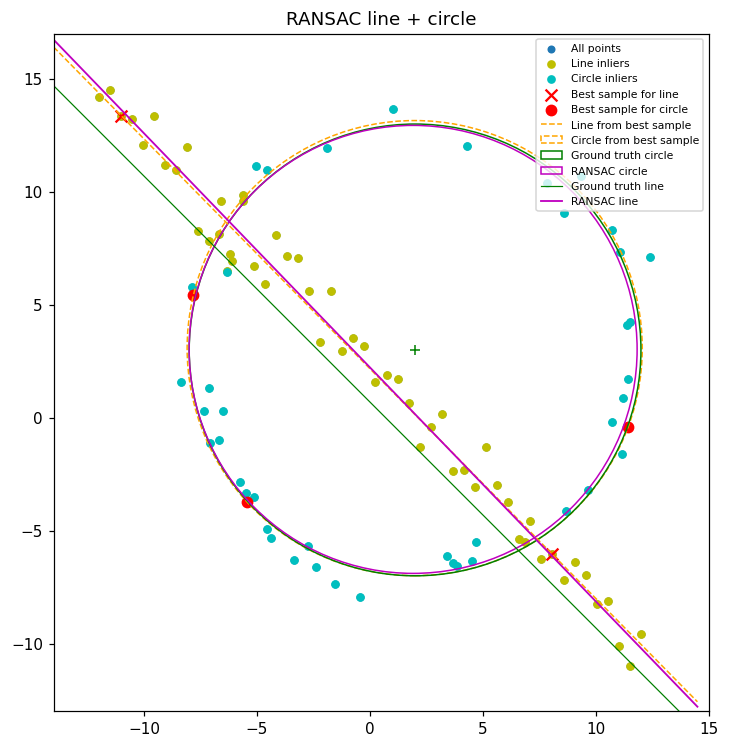

In [19]:
def plot_result(X, res_line, res_circ, remnant_idx, title="RANSAC line + circle"):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.scatter(*X.T, s=18, c="tab:blue", label="All points")
    ax.scatter(*X[res_line["inliers"]].T, s=22, c="y", label="Line inliers")
    circ_in_global = remnant_idx[res_circ["inliers"]]
    ax.scatter(*X[circ_in_global].T, s=22, c="c", label="Circle inliers")

    ls = X[res_line["sample"]]
    ax.scatter(*ls.T, marker="x", c="r", s=60, label="Best sample for line")
    cs = X[remnant_idx[res_circ["sample"]]]
    ax.scatter(*cs.T, c="r", s=45, label="Best sample for circle")

    xs = np.array([-14, 14.5])
    def draw_line(mdl, **kw):
        a, b, d = mdl
        if abs(b) > 1e-9: ax.plot(xs, (d - a * xs) / b, **kw)
        else: ax.axvline(d / a, **kw)
    draw_line(res_line["sample_model"], color="orange", ls="--", lw=1, label="Line from best sample")
    ax.add_patch(plt.Circle(res_circ["sample_model"][:2], res_circ["sample_model"][2],
                            fill=False, color="orange", ls="--", lw=1, label="Circle from best sample"))
    ax.add_patch(plt.Circle((x0_gt, y0_gt), r, fill=False, color="g", label="Ground truth circle"))
    ax.add_patch(plt.Circle(res_circ["model"][:2], res_circ["model"][2], fill=False, color="m", label="RANSAC circle"))
    ax.plot(xs, m * xs + b, color="g", lw=0.8, label="Ground truth line")
    draw_line(res_line["model"], color="m", lw=1.2, label="RANSAC line")
    ax.plot(x0_gt, y0_gt, "g+")
    ax.set_xlim(-14, 15); ax.set_ylim(-13, 17); ax.set_aspect("equal")
    ax.legend(fontsize=7, loc="upper right"); ax.set_title(title); plt.show()

plot_result(X, res_line, res_circ, remnant_idx)

### Q2 – Discussion (b/c)
* The RANSAC line/circle agree closely with the ground truth (compare printed numbers). The small residual difference comes from the noise itself: the final fit uses
  all inliers (TLS for the line, `minimize` for the circle) so it is better than the raw 2/3-point sample models (dashed orange).
* Choosing the thresholds from the known noise level (≈1.5–2σ) is the key design decision: too small → true points are rejected and the model is under-supported;
  too large → outliers (e.g. circle points near the line) join the consensus and bias the fit.
* The minimum consensus is a sanity check: a hypothesis with fewer than 35 supporters is not trusted as a real structure.

## Q2(d) – What happens if we fit the circle first?
Run RANSAC for the circle on the **full** point set (line points included) with the same threshold.

**Expected behaviour / explanation.** The point set is ~50 % circle, ~50 % line. For circle-RANSAC the 50 line points are *structured outliers*, not random noise:
* The inlier ratio is only ≈0.5 (versus ≈0.9 after removing the line), so a random 3-point sample is all-inliers with probability ≈0.5³ = 12 % (vs ≈70 %), which needs many more iterations.
* More importantly, samples with points from both structures can define a circle that passes through an **arc of the real circle plus the two places where the line crosses it**,
  or a large-radius circle that hugs the line over a stretch; such hypotheses gather a consensus comparable to the true circle, so the "best" circle can be biased or wrong (centre/radius shifted). On some seeds the circle is still recovered well, but its consensus is inflated (> 50 true circle points) because line points get absorbed, and it takes many more iterations to find reliably.
* The true circle's consensus (≈47) is also partially contaminated by line points lying within the radial threshold where the line crosses the circle.

Removing the line first (simple, robust structure, 2-point sample) strips out the largest source of structured outliers, which makes the harder 3-point circle estimation reliable. The cell below shows the result.

circle-first: inliers=57, centre=(1.90, 3.02), r=9.88   (ground truth (2, 3), 10)
line-first  : inliers=45, centre=(1.91, 3.02), r=9.92


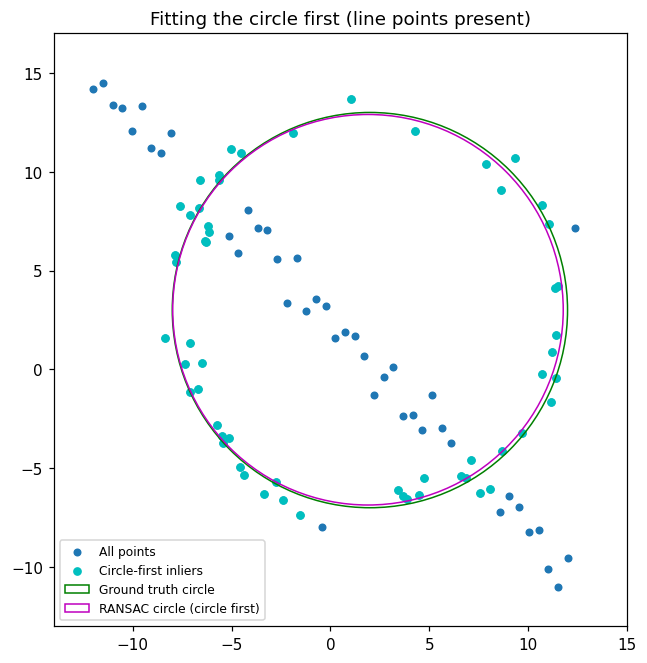

In [20]:
res_circ_first = ransac_circle(X, CIRC_THRESH, CIRC_MIN, CIRC_ITERS)
cx2, cy2, cr2 = res_circ_first["model"]
print(f"circle-first: inliers={res_circ_first['count']}, centre=({cx2:.2f}, {cy2:.2f}), r={cr2:.2f}   (ground truth (2, 3), 10)")
print(f"line-first  : inliers={res_circ['count']}, centre=({cx:.2f}, {cy:.2f}), r={cr:.2f}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(*X.T, s=18, label="All points")
ax.scatter(*X[res_circ_first["inliers"]].T, s=22, c="c", label="Circle-first inliers")
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, fill=False, color="g", label="Ground truth circle"))
ax.add_patch(plt.Circle((cx2, cy2), cr2, fill=False, color="m", label="RANSAC circle (circle first)"))
ax.set_xlim(-14, 15); ax.set_ylim(-13, 17); ax.set_aspect("equal"); ax.legend(fontsize=8)
ax.set_title("Fitting the circle first (line points present)"); plt.show()

*Interpretation:* compare the two printed lines and the plot. If the circle-first estimate is off (or has an inflated/deflated consensus that includes line points), that confirms the structured-outlier argument.
Since the data are random, re-run with different seeds (remove `np.random.seed(0)`) to see how often circle-first fails or needs many more iterations.

---
# Q3 – Homography: superimposing a flag on a planar surface

**Method.** Click 4 corners of a planar surface (wall/window/façade) in the architectural image, in order **TL, TR, BR, BL**. The flag corners are
$(0,0),(w,0),(w,h),(0,h)$. We estimate the 3×3 homography $H$ with $\tilde{x}'\sim H\tilde{x}$ using the **Direct Linear Transform** (each correspondence gives two rows of $A h = 0$; $h$ = right singular vector of the smallest singular value),
warp the flag with `cv.warpPerspective`, build a mask by warping an all-white image, and **alpha-blend**:
$I_{out}=(1-\alpha M)\,I_{arch}+\alpha M\,I_{flag}$.

**Rationale for my choice of image pairs** (write your own, e.g.): *pair 1* – a building with a large, clearly planar façade seen at an oblique angle, so the perspective distortion shows the homography working;
*pair 2* – a different viewpoint / flag with different aspect ratio, to show the method is independent of the scene. A homography is exact only for **planar** surfaces, so planar walls and windows were chosen.

**Step 1 (optional, interactive, run once per pair):** pick the points. Needs a GUI backend (`%matplotlib qt` or `%matplotlib tk`). Paste the printed lists into the config in Step 2.

In [21]:
# OPTIONAL: run once to pick points interactively. Click TL, TR, BR, BL on the planar region.
PICK_IMAGE = "images/arch1.jpg"        # CONFIG
# %matplotlib qt
# img = cv.imread(PICK_IMAGE)
# plt.figure(figsize=(10, 7)); plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)); plt.title("click 4 points: TL, TR, BR, BL")
# pts = plt.ginput(4, timeout=0); plt.close()
# print([[round(x), round(y)] for x, y in pts])
# %matplotlib inline

In [22]:
# CONFIG: two image pairs. points = [[x,y]*4] in order TL, TR, BR, BL (set to None until you have picked them).
PAIRS = [
    dict(arch="images/arch1.jpg", flag="images/flag1.png", points=None, alpha=0.7),
    dict(arch="images/arch2.jpg", flag="images/flag2.png", points=None, alpha=0.7),
]

def homography_dlt(src, dst):
    """src, dst: (n,2), n>=4. Returns 3x3 H with dst ~ H src."""
    A = []
    for (x, y), (u, v) in zip(src, dst):
        A.append([-x, -y, -1, 0, 0, 0, u * x, u * y, u])
        A.append([0, 0, 0, -x, -y, -1, v * x, v * y, v])
    _, _, Vt = np.linalg.svd(np.array(A, float))
    H = Vt[-1].reshape(3, 3)
    return H / H[2, 2]

def overlay_flag(arch, flag, pts, alpha=0.7):
    h, w = flag.shape[:2]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    dst = np.float32(pts)
    H = homography_dlt(src, dst)
    H_cv = cv.getPerspectiveTransform(src, dst)
    print("max |H_dlt - H_cv| =", np.abs(H - H_cv / H_cv[2, 2]).max())   # sanity check
    size = (arch.shape[1], arch.shape[0])
    warped = cv.warpPerspective(flag, H, size)
    mask = cv.warpPerspective(np.full(flag.shape[:2], 1.0, np.float32), H, size)[..., None]
    out = arch * (1 - alpha * mask) + warped * (alpha * mask)
    return out.astype(np.uint8), H

for i, p in enumerate(PAIRS, 1):
    if p["points"] is None:
        print(f"Pair {i}: points not set -> run the picking cell and paste the coordinates in PAIRS. Skipping.")
        continue
    arch, flag = cv.imread(p["arch"]), cv.imread(p["flag"])
    assert arch is not None and flag is not None, "check image paths"
    out, H = overlay_flag(arch, flag, p["points"], p["alpha"])
    print(f"Pair {i} homography:\n", np.round(H, 4))
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    for a_, im_, t_ in zip(ax, [arch, flag, out], ["architecture + clicked points", "flag", "result"]):
        a_.imshow(cv.cvtColor(im_, cv.COLOR_BGR2RGB)); a_.set_title(t_); a_.axis("off")
    ax[0].plot(*np.array(p["points"] + [p["points"][0]]).T, "r-o")
    plt.show()

Pair 1: points not set -> run the picking cell and paste the coordinates in PAIRS. Skipping.
Pair 2: points not set -> run the picking cell and paste the coordinates in PAIRS. Skipping.


### Q3 – Discussion
* Four non-collinear correspondences give exactly 8 equations for the 8 DoF of $H$; clicking errors of a few pixels directly shift the flag corners, so click carefully on sharp corners (more points + least squares would be more robust).
* The flag follows the perspective of the wall (parallel lines converge), which is exactly what a homography models for a plane. It looks correct *only* on the plane the points were clicked on – the flag does not respect depth/occlusion (e.g. protruding window frames).
* Alpha blending (α≈0.7) keeps the wall texture visible so the flag looks "painted on"; α=1 would look like a sticker.

---
# Q4 – PCB alignment with SIFT + RANSAC homography

**Pipeline**
1. **(a)** `sift = cv2.SIFT_create()` → keypoints + 128-D descriptors in the template (`AECC1.jpg`) and in each PCB image.
2. **(b)** `cv2.BFMatcher()` (L2 norm) with `knnMatch(k=2)` + **Lowe's ratio test** (0.75) to remove ambiguous matches; then `cv2.findHomography(..., cv2.RANSAC, 5.0)` rejects the remaining wrong matches; draw the RANSAC-inlier matches.
3. **(c)** `cv2.warpPerspective(pcb, H, template_size)` maps the PCB image into the template frame; `cv2.absdiff` of (grayscale) aligned vs template gives the difference image.
4. **(d)** Repeat for every PCB image.

PCB images: ['images\\AECC2.jpg', 'images\\AECC3.jpg', 'images\\AECC4.jpg']
template keypoints: 14272
AECC2.jpg: keypoints=12315, good matches=4322, RANSAC inliers=3847


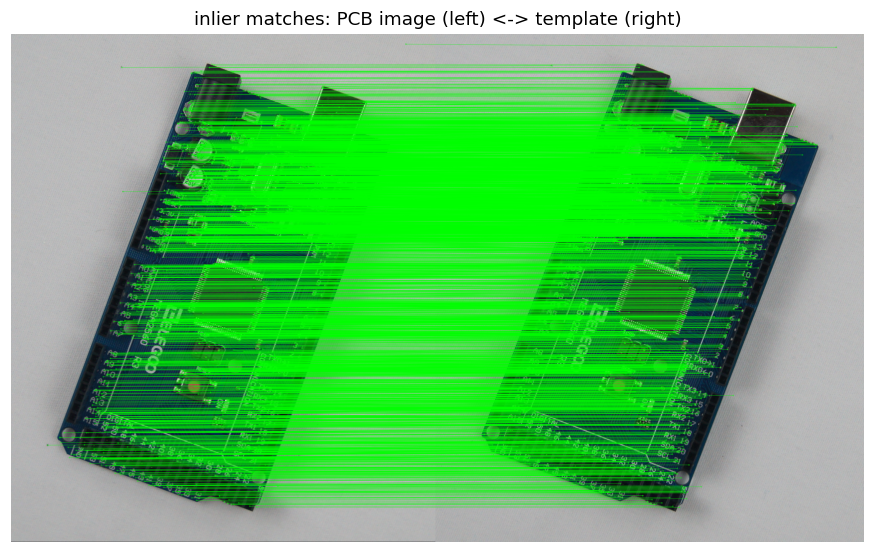

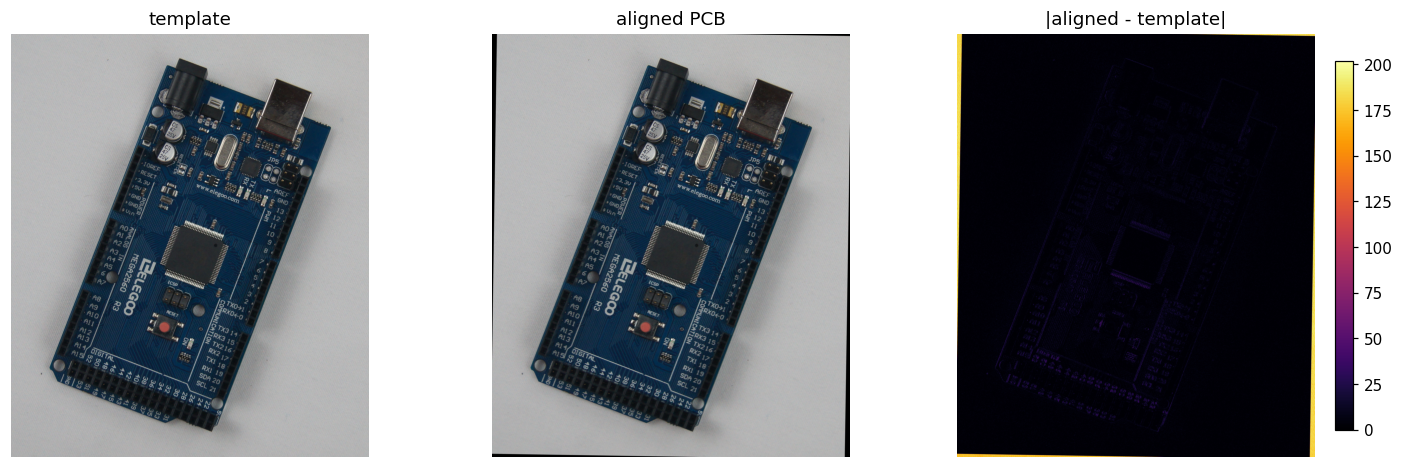

In [23]:
# CONFIG ---------------------------------------------------------------
TEMPLATE_PATH = "images/AECC1.jpg"
PCB_GLOB      = "images/AECC*.*"        # change if your PCB images are named differently / live in another folder
RATIO         = 0.75
RANSAC_THRESH = 5.0
# ----------------------------------------------------------------------
template = cv.imread(TEMPLATE_PATH)
assert template is not None, f"Could not read {TEMPLATE_PATH}"
pcb_paths = [p for p in sorted(glob.glob(PCB_GLOB)) if os.path.abspath(p) != os.path.abspath(TEMPLATE_PATH)]
print("PCB images:", pcb_paths)

sift = cv.SIFT_create()
bf = cv.BFMatcher()
tmpl_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)
kp_t, des_t = sift.detectAndCompute(tmpl_gray, None)
print("template keypoints:", len(kp_t))

def align_to_template(pcb):
    g = cv.cvtColor(pcb, cv.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(g, None)                       # (a)
    knn = bf.knnMatch(des, des_t, k=2)                              # query = pcb, train = template
    good = [m for m, n in (p for p in knn if len(p) == 2) if m.distance < RATIO * n.distance]
    src = np.float32([kp[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(src, dst, cv.RANSAC, RANSAC_THRESH)  # (b)
    aligned = cv.warpPerspective(pcb, H, (template.shape[1], template.shape[0]))   # (c)
    diff = cv.absdiff(cv.cvtColor(aligned, cv.COLOR_BGR2GRAY), tmpl_gray)
    return dict(kp=kp, good=good, H=H, mask=mask.ravel().astype(int).tolist(), aligned=aligned, diff=diff)

def show_result(path, full=True):
    pcb = cv.imread(path)
    R = align_to_template(pcb)
    print(f"{os.path.basename(path)}: keypoints={len(R['kp'])}, good matches={len(R['good'])}, RANSAC inliers={sum(R['mask'])}")
    if full:
        vis = cv.drawMatches(pcb, R["kp"], template, kp_t, R["good"], None, matchesMask=R["mask"],
                             matchColor=(0, 255, 0), flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        show(vis, "inlier matches: PCB image (left) <-> template (right)", (14, 6))
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    ax[0].imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB)); ax[0].set_title("template")
    ax[1].imshow(cv.cvtColor(R["aligned"], cv.COLOR_BGR2RGB)); ax[1].set_title("aligned PCB")
    im_ = ax[2].imshow(R["diff"], cmap="inferno"); ax[2].set_title("|aligned - template|"); plt.colorbar(im_, ax=ax[2], fraction=0.046)
    for a_ in ax: a_.axis("off")
    plt.show()
    return R

# (a)-(c) detailed view for the first PCB image
if pcb_paths:
    _ = show_result(pcb_paths[0], full=True)

## Q4(d) – All PCB images

AECC2.jpg: keypoints=12315, good matches=4322, RANSAC inliers=3847


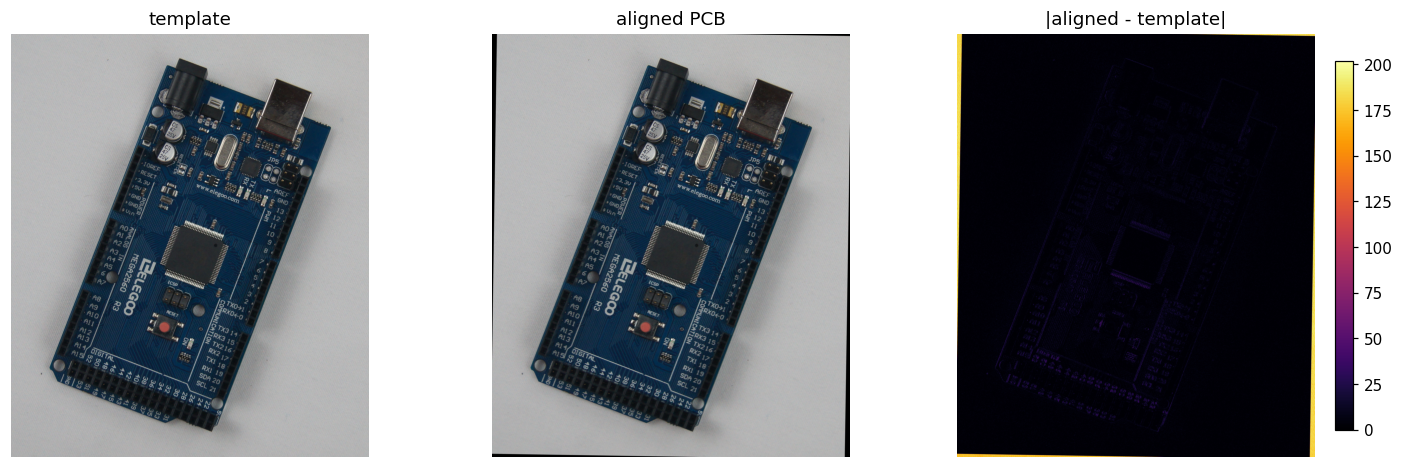

AECC3.jpg: keypoints=15198, good matches=5629, RANSAC inliers=5006


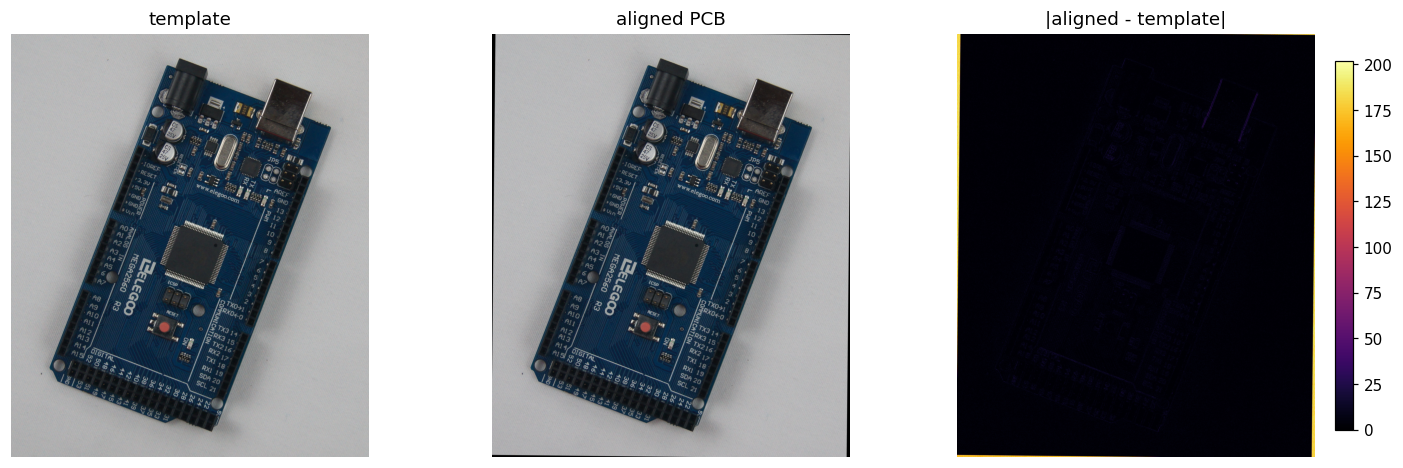

AECC4.jpg: keypoints=11610, good matches=3830, RANSAC inliers=3402


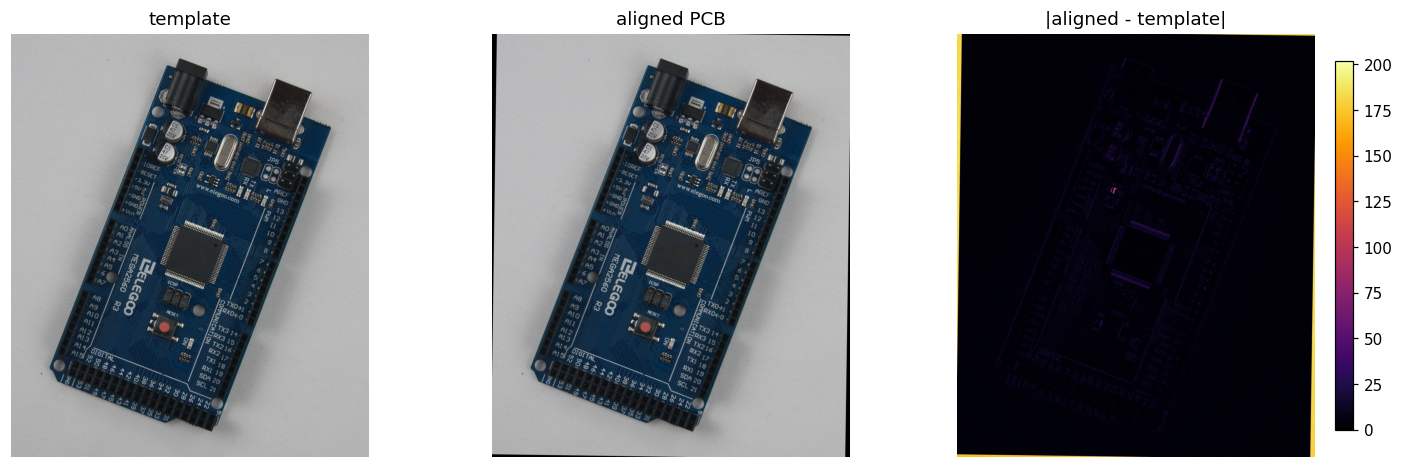

In [24]:
results = {}
for p in pcb_paths:
    results[p] = show_result(p, full=False)

## Q4(e) – Why do the USB Type-B port, capacitors and reset button show a high difference?

A homography is exact **only for a planar scene** (or a pure camera rotation). After warping, the PCB *board plane* lines up with the template, so flat areas (traces, silkscreen, the board surface) cancel, but:

1. **Out-of-plane height (parallax).** The USB-B port, electrolytic capacitors and the push-button stand tens of millimetres above the board. A point at height *h* is displaced differently from a board-level point when the camera viewpoint changes, so the single plane-induced homography cannot align them → residual edges/double images, largest for the **tallest components** (USB port, capacitors) and for larger viewpoint changes.
2. **Specular / metallic surfaces.** The USB shell, capacitor tops and the button are shiny or have different reflectance; the highlights move with viewpoint and lighting, producing intensity differences even if geometry were perfectly aligned.
3. **Illumination and exposure differences** between shots (shadows cast by tall parts, white balance) change pixel intensities of 3-D parts more than of the flat board.
4. **Small registration error and interpolation.** SIFT features lie mostly on the textured board, so the fitted homography is dominated by the board plane; small errors (sub-pixel/few-pixel) and bilinear resampling create strong differences at *sharp edges*, which these high-contrast components have a lot of.
5. **Real differences** – e.g. the reset button might be in a different state/position or a component may differ/be missing between boards, which is exactly what difference imaging is supposed to reveal.

*Mitigations:* shoot from nearly the same viewpoint (small baseline), use diffuse lighting, use more precise/local alignment (e.g. per-region homographies or a 3-D model), photometric normalisation before differencing, and blur/threshold the difference image to suppress thin edge artefacts.